In [11]:
import numpy as np 
import xarray as xr

#my own classes
import sys
sys.path.append("/emmy-noether/home/mf671/github/wave_activity_persistence")
import main_functions as mf

import time
start_time = time.time()

import matplotlib.pyplot as plt

In [49]:
%cd /home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_st_KS/tot
!pwd

/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot
/home/links/mf671/DATA/isca_data/exeter_project_mf_baseline_KS/tot


In [50]:
ds = xr.open_dataset('ts_daily_2.5x2.5_2-51.nc')#.isel(time=slice(0, 1000))
ds = ds.sel(lat=slice(0, 90))

In [51]:
ts = ds['temp'][:,0,:,:]
lon = ds['lon']
lat = ds['lat']

In [52]:
data = mf.calculate_local_wave_activity(ds, ts, monotonic_decreasing=True, planet_radius=6371.e3, n_quantity_levels=40)

running equiv lat calculation


/emmy-noether/home/mf671/github/wave_activity_persistence/main_functions.py:100: UserWarning: Warning: converting a masked element to nan.
  eq_area[zidx, pvidx] = np.ma.masked_where(pv[zidx, ...] <= pv_levs[zidx,


finished equiv lat calculation
finished interpolating to native grid
finished anom calculation


100%|███████████████████████████████████████████████████████████████████████| 37/37 [02:08<00:00,  3.47s/it]


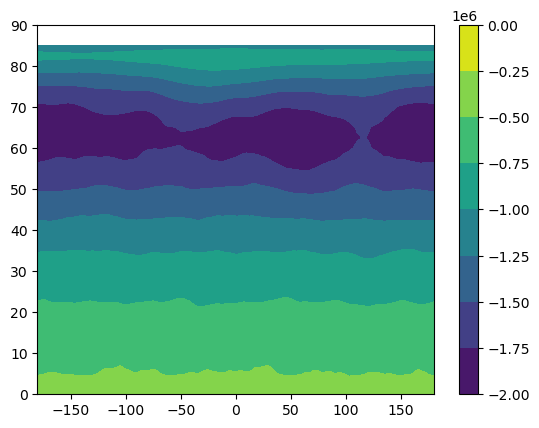

In [62]:
plt.contourf(lon,lat,data.lwa.mean('time'))
plt.colorbar()